# Transformers — Notebook 01
## Preparación de la serie de tiempo y modelos de referencia

**Problema.** Pronosticar la **temperatura mínima diaria de los próximos 7 días** en Melbourne (Australia) a partir de los **60 días anteriores**.

**Dataset.** *Daily Minimum Temperatures in Melbourne, 1981–1990* (Australian Bureau of Meteorology; distribuido por J. Brownlee): 3 650 observaciones diarias en °C.

Contenido:
1. Carga, limpieza y análisis exploratorio (tendencia, estacionalidad, autocorrelación).
2. Partición **cronológica** train / validación / test (sin barajar: no se puede usar el futuro para predecir el pasado).
3. Escalado ajustado sólo con train y **codificación cíclica** del día del año.
4. Construcción de **ventanas deslizantes** 60 → 7.
5. **Modelos de referencia**: persistencia, climatología y regresión lineal (Ridge). Cualquier red neuronal debe superarlos para ser útil.

> Google Colab: `Entorno de ejecución → Ejecutar todas`. El dataset se descarga automáticamente desde GitHub.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

### Utilidades comunes (`src/ts_utils.py`)

In [2]:
"""Utilidades de series de tiempo: carga, partición cronológica, escalado, ventanas, líneas base y métricas."""
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOOKBACK = 60          # días de contexto que ve el modelo
HORIZON = 7            # días a pronosticar
SPLITS = {"train": ("1981-01-01", "1986-12-31"), "val": ("1987-01-01", "1988-12-31"), "test": ("1989-01-01", "1990-12-31")}

for d in ("data", "figures", "results", "modelos"):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load_series(path: str = "data/daily-min-temperatures.csv") -> pd.Series:
    """Temperatura mínima diaria de Melbourne (°C), con frecuencia diaria completa."""
    if not os.path.exists(path):
        pd.read_csv(URL).to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["Date"])
    s = pd.to_numeric(df["Temp"], errors="coerce")
    s.index = df["Date"]
    full = s.asfreq("D")                       # inserta las fechas faltantes como NaN
    return full


def calendar_features(index: pd.DatetimeIndex) -> np.ndarray:
    """Codificación cíclica del día del año: (sin, cos). Evita el salto artificial 31-dic → 1-ene."""
    doy = index.dayofyear.values
    ang = 2 * np.pi * doy / 365.25
    return np.stack([np.sin(ang), np.cos(ang)], axis=1).astype("float32")


class Scaler:
    """Estandarización z-score ajustada SÓLO con el conjunto de entrenamiento."""
    def fit(self, x):
        self.mu, self.sigma = float(np.mean(x)), float(np.std(x)); return self
    def transform(self, x): return (np.asarray(x) - self.mu) / self.sigma
    def inverse(self, z): return np.asarray(z) * self.sigma + self.mu


def make_windows(values_z, feats, dates, start, end, lookback=LOOKBACK, horizon=HORIZON):
    """Ventanas deslizantes: X = [temp_z, sin, cos] de los `lookback` días previos,
    y = temp_z de los `horizon` días siguientes. Sólo se aceptan ventanas cuyo PRIMER día
    a pronosticar cae en [start, end] y cuyo último día objetivo no supera `end`
    (el contexto sí puede venir del periodo anterior, que ya es pasado conocido)."""
    X_in = np.concatenate([values_z[:, None], feats], axis=1).astype("float32")
    t0 = np.searchsorted(dates, np.datetime64(start)); t1 = np.searchsorted(dates, np.datetime64(end), side="right")
    X, Y, D, F = [], [], [], []
    for t in range(max(t0, lookback), t1 - horizon + 1):
        X.append(X_in[t - lookback:t]); Y.append(values_z[t:t + horizon])
        F.append(feats[t:t + horizon]); D.append(dates[t])
    return np.array(X), np.array(Y, dtype="float32"), np.array(F, dtype="float32"), np.array(D)


def prepare(lookback=LOOKBACK, horizon=HORIZON):
    """Pipeline completo: serie limpia, escalador y ventanas por partición."""
    s = load_series()
    n_missing = int(s.isna().sum())
    s = s.interpolate(limit_direction="both")
    dates = s.index.values
    tr_mask = (s.index >= SPLITS["train"][0]) & (s.index <= SPLITS["train"][1])
    scaler = Scaler().fit(s.values[tr_mask])
    z = scaler.transform(s.values).astype("float32")
    feats = calendar_features(s.index)
    data = {"series": s, "scaler": scaler, "n_missing": n_missing, "z": z, "feats": feats}
    for name, (a, b) in SPLITS.items():
        X, Y, F, D = make_windows(z, feats, dates, a, b, lookback, horizon)
        data[name] = {"X": X, "Y": Y, "F": F, "dates": D}
    return data


# ----------------------------------------------------------------------------- líneas base
def persistence(X):
    """Pronóstico ingenuo: los próximos días serán iguales al último observado."""
    return np.repeat(X[:, -1:, 0], HORIZON, axis=1)


def climatology_model(series: pd.Series, scaler: Scaler, window: int = 15):
    """Media por día del año en train (suavizada con media móvil circular). Devuelve f(fechas)->z."""
    tr = series[SPLITS["train"][0]:SPLITS["train"][1]]
    clim = tr.groupby(tr.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    ext = pd.concat([clim.iloc[-window:], clim, clim.iloc[:window]])
    smooth = ext.rolling(window, center=True).mean().iloc[window:-window]
    def predict(first_dates):
        out = []
        for d0 in pd.to_datetime(first_dates):
            days = pd.date_range(d0, periods=HORIZON, freq="D").dayofyear
            out.append(scaler.transform(smooth.loc[days].values))
        return np.array(out, dtype="float32")
    return predict, smooth


# ----------------------------------------------------------------------------- métricas
def metrics(y_true_z, y_pred_z, scaler: Scaler) -> dict:
    """MAE y RMSE en °C (global y por horizonte)."""
    yt, yp = scaler.inverse(y_true_z), scaler.inverse(y_pred_z)
    err = yp - yt
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "MAE_h": np.abs(err).mean(0).tolist(), "MAE_d1": float(np.abs(err[:, 0]).mean()),
            "MAE_d7": float(np.abs(err[:, -1]).mean())}


def save_json(obj, path):
    def conv(o):
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=conv)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

## 1. Carga y limpieza

In [3]:
raw = load_series()
print(f"Periodo: {raw.index.min().date()} → {raw.index.max().date()} | días: {len(raw)} | faltantes: {int(raw.isna().sum())}")
print("Fechas faltantes:", [str(d.date()) for d in raw[raw.isna()].index])
raw.describe().round(2)

Periodo: 1981-01-01 → 1990-12-31 | días: 3652 | faltantes: 2
Fechas faltantes: ['1984-12-31', '1988-12-31']


count    3650.00
mean       11.18
std         4.07
min         0.00
25%         8.30
50%        11.00
75%        14.00
max        26.30
Name: Temp, dtype: float64

La serie original tiene 3 650 filas, pero 10 años contienen 3 652 días: faltan los dos 31 de diciembre de los años bisiestos (1984 y 1988). Se reindexa a frecuencia diaria y los dos huecos se rellenan por **interpolación lineal**, lo que preserva la continuidad que necesitan las ventanas.

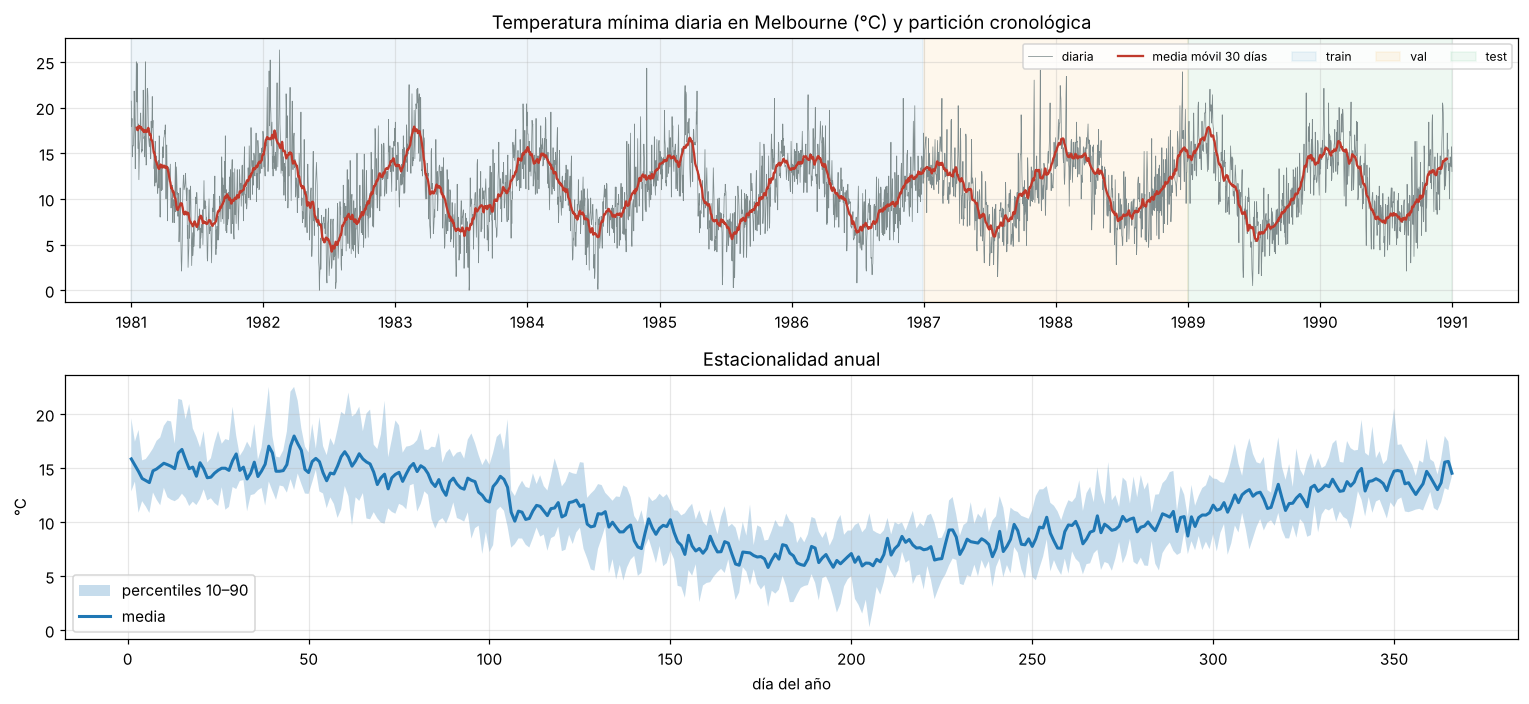

In [4]:
data = prepare()
s, scaler = data["series"], data["scaler"]
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5))
ax[0].plot(s.index, s.values, lw=0.5, color="#7f8c8d", label="diaria")
ax[0].plot(s.index, s.rolling(30, center=True).mean(), color="#c0392b", lw=1.5, label="media móvil 30 días")
for name, (a, b), col in zip(SPLITS, SPLITS.values(), ["#2e86c1", "#f39c12", "#27ae60"]):
    ax[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=0.08, label=name)
ax[0].set_title("Temperatura mínima diaria en Melbourne (°C) y partición cronológica"); ax[0].legend(ncol=5, fontsize=8)
by_doy = s.groupby(s.index.dayofyear)
ax[1].fill_between(range(1, 367), by_doy.quantile(0.1), by_doy.quantile(0.9), alpha=0.25, label="percentiles 10–90")
ax[1].plot(range(1, 367), by_doy.mean(), lw=2, label="media")
ax[1].set_xlabel("día del año"); ax[1].set_ylabel("°C"); ax[1].set_title("Estacionalidad anual"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/01_serie.png", bbox_inches="tight"); plt.show()

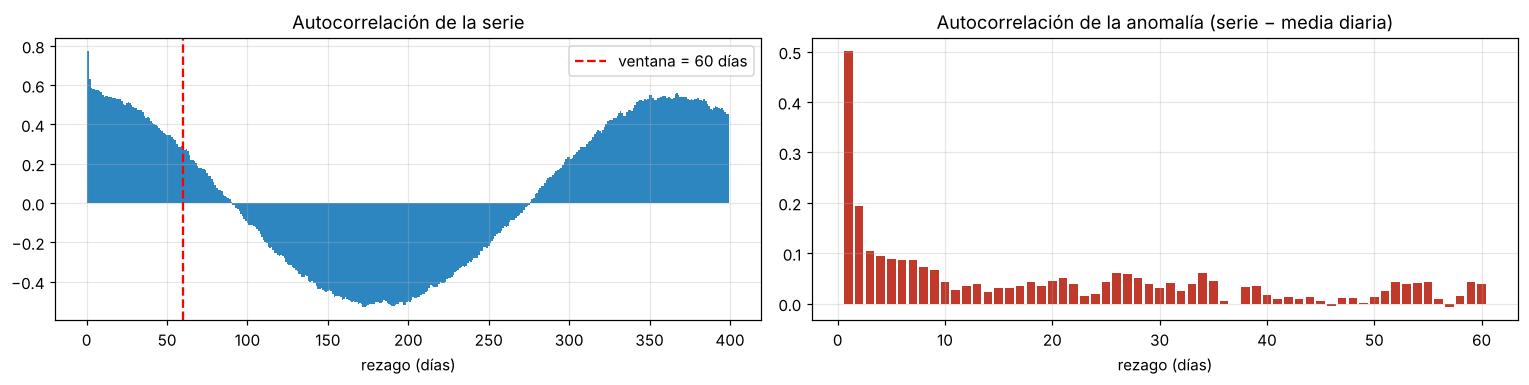

Autocorrelación rezago 1: 0.775 | rezago 7: 0.576 | rezago 365: 0.535
Anomalía — rezago 1: 0.502 | rezago 3: 0.105 | rezago 7: 0.087


In [5]:
lags = np.arange(1, 400)
acf = [s.autocorr(l) for l in lags]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].bar(lags, acf, width=1, color="#2e86c1"); ax[0].axvline(LOOKBACK, ls="--", c="red", label=f"ventana = {LOOKBACK} días")
ax[0].set_title("Autocorrelación de la serie"); ax[0].set_xlabel("rezago (días)"); ax[0].legend()
anom = s - s.groupby(s.index.dayofyear).transform("mean")
acf_a = [anom.autocorr(l) for l in lags[:60]]
ax[1].bar(lags[:60], acf_a, width=0.8, color="#c0392b"); ax[1].set_title("Autocorrelación de la anomalía (serie − media diaria)")
ax[1].set_xlabel("rezago (días)")
plt.tight_layout(); plt.savefig("figures/01_autocorrelacion.png", bbox_inches="tight"); plt.show()
print(f"Autocorrelación rezago 1: {acf[0]:.3f} | rezago 7: {acf[6]:.3f} | rezago 365: {acf[364]:.3f}")
print(f"Anomalía — rezago 1: {acf_a[0]:.3f} | rezago 3: {acf_a[2]:.3f} | rezago 7: {acf_a[6]:.3f}")

**Lectura.** La serie tiene una **estacionalidad anual** fuerte (≈ 7 °C en julio, ≈ 15 °C en enero) y una variabilidad diaria grande. Una vez descontado el ciclo anual, la **anomalía** sólo conserva memoria de unos pocos días (autocorrelación 0.50 a 1 día que cae a 0.10 a los 3 días). Por eso el modelo necesita dos fuentes de información: el **contexto reciente** (últimos días) y la **posición en el año**, que se entrega como (sin, cos) del día del año.

## 2. Partición, escalado y ventanas

| Conjunto | Periodo | Uso |
|---|---|---|
| Train | 1981–1986 (6 años) | Ajustar pesos y estadísticos de escalado |
| Validación | 1987–1988 (2 años) | *Early stopping* y comparación de configuraciones |
| Test | 1989–1990 | Evaluación final, una sola vez |

Se usan **dos años de validación**: con un solo año, la variabilidad meteorológica de ese año hacía que el *early stopping* se detuviera en la segunda época, aunque el modelo seguía mejorando en otros años.

Cada ejemplo es una ventana: **X** = 60 días × 3 variables [temperatura estandarizada, sin(día del año), cos(día del año)] y **y** = temperatura estandarizada de los 7 días siguientes. El contexto de una ventana de validación o test puede incluir días del periodo anterior (es pasado conocido), pero ningún objetivo cruza la frontera de su conjunto.

In [6]:
print(f"Escalado (sólo train): media = {scaler.mu:.3f} °C, desviación = {scaler.sigma:.3f} °C")
rows = []
for k in ("train", "val", "test"):
    rows.append({"conjunto": k, "ventanas": len(data[k]["Y"]), "X": str(data[k]["X"].shape), "y": str(data[k]["Y"].shape),
                 "primer día objetivo": str(data[k]["dates"][0])[:10], "último día objetivo": str(data[k]["dates"][-1])[:10]})
pd.DataFrame(rows).set_index("conjunto")

Escalado (sólo train): media = 11.005 °C, desviación = 4.160 °C


,ventanas,X,y,primer día objetivo,último día objetivo
conjunto,,,,,
train,2125,"(2125, 60, 3)","(2125, 7)",1981-03-02,1986-12-25
val,725,"(725, 60, 3)","(725, 7)",1987-01-01,1988-12-25
test,724,"(724, 60, 3)","(724, 7)",1989-01-01,1990-12-25


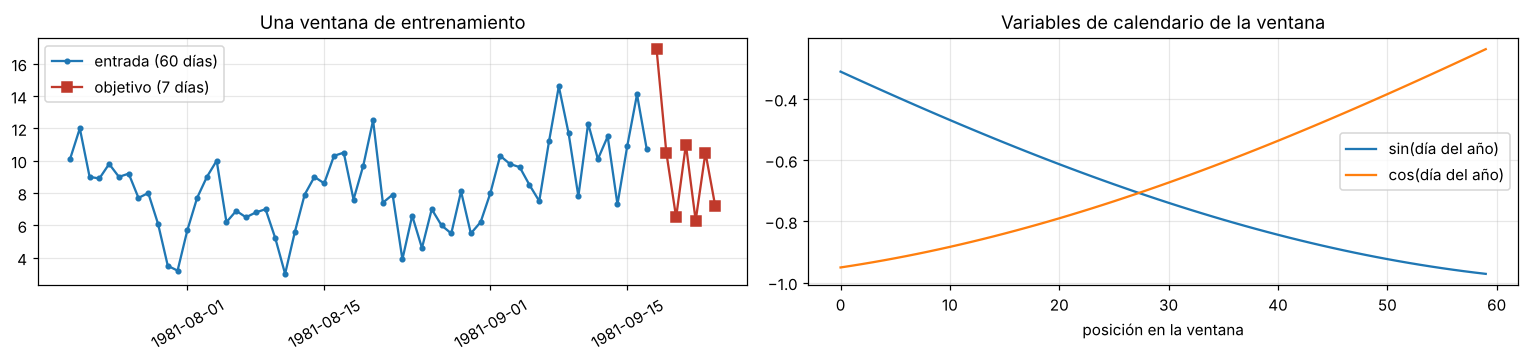

In [7]:
i = 200
Xw, Yw = data["train"]["X"][i], data["train"]["Y"][i]
d0 = pd.Timestamp(data["train"]["dates"][i])
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
ax[0].plot(pd.date_range(end=d0 - pd.Timedelta(days=1), periods=LOOKBACK), scaler.inverse(Xw[:, 0]), "o-", ms=3, label="entrada (60 días)")
ax[0].plot(pd.date_range(d0, periods=HORIZON), scaler.inverse(Yw), "s-", c="#c0392b", label="objetivo (7 días)")
ax[0].set_title("Una ventana de entrenamiento"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
ax[1].plot(Xw[:, 1], label="sin(día del año)"); ax[1].plot(Xw[:, 2], label="cos(día del año)")
ax[1].set_title("Variables de calendario de la ventana"); ax[1].set_xlabel("posición en la ventana"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/01_ventana.png", bbox_inches="tight"); plt.show()

## 3. Modelos de referencia
* **Persistencia:** los 7 días siguientes valen lo mismo que el último observado.
* **Climatología:** la temperatura media de ese día del año en train (suavizada con media móvil de 15 días).
* **Regresión lineal (Ridge):** combinación lineal de los 60 valores y del calendario; es el punto de comparación más exigente para las redes.

In [8]:
clim_pred, clim_curve = climatology_model(s, scaler)
Xtr = data["train"]["X"].reshape(len(data["train"]["X"]), -1)
ridge = Ridge(alpha=1.0).fit(Xtr, data["train"]["Y"])
base = {}
for name, f in {"Persistencia": lambda k: persistence(data[k]["X"]),
                "Climatología": lambda k: clim_pred(data[k]["dates"]),
                "Regresión lineal (Ridge)": lambda k: ridge.predict(data[k]["X"].reshape(len(data[k]["X"]), -1))}.items():
    base[name] = {k: metrics(data[k]["Y"], f(k), scaler) for k in ("val", "test")}
tab = pd.DataFrame({n: {"MAE val": v["val"]["MAE"], "MAE test": v["test"]["MAE"], "RMSE test": v["test"]["RMSE"],
                        "MAE test día 1": v["test"]["MAE_d1"], "MAE test día 7": v["test"]["MAE_d7"]} for n, v in base.items()}).T
tab.round(3)

,MAE val,MAE test,RMSE test,MAE test día 1,MAE test día 7
Persistencia,2.785,2.624,3.321,1.958,2.750
Climatología,2.264,2.024,2.593,2.031,2.014
Regresión lineal (Ridge),2.169,1.994,2.568,1.765,2.026


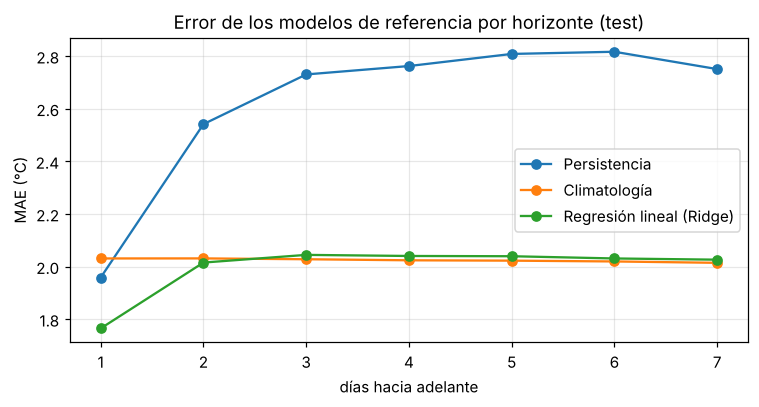

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for n, v in base.items():
    ax.plot(range(1, HORIZON + 1), v["test"]["MAE_h"], "o-", label=n)
ax.set_xlabel("días hacia adelante"); ax.set_ylabel("MAE (°C)"); ax.set_title("Error de los modelos de referencia por horizonte (test)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/01_baselines.png", bbox_inches="tight"); plt.show()
save_json({"n_missing": data["n_missing"], "scaler": {"mu": scaler.mu, "sigma": scaler.sigma},
           "ventanas": {k: len(data[k]["Y"]) for k in ("train", "val", "test")}, "baselines": base}, "results/01_baselines.json")

## 4. Conclusiones
* La serie (3 652 días tras completar 2 fechas faltantes) combina un **ciclo anual** fuerte con mucha variabilidad diaria. La anomalía respecto al ciclo tiene memoria corta: autocorrelación 0.50 a un día y apenas 0.10 a tres días.
* Con partición cronológica (train 1981–1986, validación 1987–1988, test 1989–1990) y escalado ajustado sólo con train se obtienen 2 125 / 725 / 724 ventanas 60 → 7.
* **Persistencia** (MAE test 2.62 °C) es buena sólo para el día siguiente (1.96 °C) y se degrada con el horizonte. **Climatología** (2.02 °C) no usa el contexto reciente y su error es casi plano. La **regresión lineal** combina ambas fuentes y es la referencia más exigente: 1.99 °C de MAE global y 1.77 °C para el día 1.
* Por la memoria corta de la anomalía, más allá de 2–3 días el pronóstico tiende a la climatología: el margen de mejora de cualquier modelo está sobre todo en los primeros días.